# 03 - Phase 3: brain encoder, splits, decoding gate, synthetic tasks
**Inputs (Add Input):** the dataset that contains `X_region.npy` and `M_region.csv` (your Phase 2 output).
**Settings:** Accelerator **None**, Internet **Off** is fine. Runtime about 10 to 15 minutes.

| Step | Cell | What it does |
|---|---|---|
| 3.1 | B | Brain encoder (shared by real and control data) + smoke test |
| 3.2 | C | Subject-grouped folds with ID / OOD-load test sets |
| 3.3 | D | Leakage checks (asserts) |
| 3.4 | E, F | **Gate:** can brain features decode load / match above chance? |
| 3.5 | G, H | Surrogate memory sets, synthetic OOD sets, ceiling check |
| | I | Save everything for Phase 4 |

In [1]:
# ---- Cell A: setup, locate and load the Phase 2 outputs ----
import os, sys, json, pathlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

OUT3 = pathlib.Path("/kaggle/working/phase3_out"); OUT3.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(OUT3))

def find(name):
    hits = []
    for root in ("/kaggle/input", "/kaggle/working"):
        hits += sorted(pathlib.Path(root).rglob(name))
    assert hits, f"{name} not found - add the Phase 2 dataset as an input to this notebook"
    return hits[0]

P2 = find("X_region.npy").parent
X = np.load(P2 / "X_region.npy")
M = pd.read_csv(P2 / "M_region.csv")
print("Phase 2 files from:", P2)
print("X:", X.shape, X.dtype, "| M:", M.shape)

need = ["subject", "session", "nTrial", "SetSize", "Match", "Correct", "ResponseTime", "clean", "fs"]
assert all(c in M.columns for c in need), [c for c in need if c not in M.columns]
assert X.shape == (3353, 4, 16, 5) and len(M) == 3353
assert (M.index.values == np.arange(len(M))).all()
assert not M.duplicated(["subject", "session", "nTrial"]).any()
C = M.clean.values.astype(bool)
print("clean trials:", int(C.sum()), "| subjects:", M.subject.nunique(), "| fs groups:", sorted(M.fs.unique()))

Phase 2 files from: /kaggle/input/datasets/rachana240906/cd-b2m-ds004752-phase2-cache/phase2_out
X: (3353, 4, 16, 5) float32 | M: (3353, 15)
clean trials: 3185 | subjects: 15 | fs groups: [np.int64(2000), np.int64(4000), np.int64(4096)]


## 3.1 Brain encoder (writes the shared library file)

In [2]:
%%writefile /kaggle/working/phase3_out/cdb2m_lib.py
# cdb2m_lib.py - shared code for CD-B2M (Phase 3 onward). Written by 03_encoder_splits.
import numpy as np, pandas as pd

CORE  = ["hippocampus", "amygdala", "parahippocampal", "lateral_temporal"]
BANDS = ["theta", "alpha", "beta", "lgamma", "hgamma"]
BIN_S = 0.5
EPOCH = {"encoding": (0, 2), "maintenance": (2, 5), "probe": (5, 8)}
PAD, SEP, MAX_LEN = 0, 1, 12          # token ids and max memory-set length


# ---------------------------------------------------------------- brain features
def win_slice(name):
    lo, hi = EPOCH[name]
    return slice(int(lo / BIN_S), int(hi / BIN_S))

def region_present(X):
    "(N, R) bool: region has data in that trial's session"
    return ~np.isnan(X).all(axis=(2, 3))

def window_features(X, window="maintenance", regions=None):
    "X (N,R,T,B) -> (N,F). Window-mean features; NaN -> 0 (data are z-scored, 0 = session mean)."
    ridx = [CORE.index(r) for r in (regions or CORE)]
    Xr = X[:, ridx]
    if window == "full":
        F = Xr.reshape(len(X), -1)
    elif window == "all3":
        F = np.concatenate([Xr[:, :, win_slice(w)].mean(2).reshape(len(X), -1) for w in EPOCH], 1)
    else:
        F = Xr[:, :, win_slice(window)].mean(2).reshape(len(X), -1)
    return np.nan_to_num(F, nan=0.0).astype(np.float32)


# ---------------------------------------------------------------- splits
def make_folds(M, n_folds=5, seed=42):
    """Subject-grouped folds, balanced over acquisition group (2000 Hz vs 4000/4096 Hz).
    Per fold: train / val on loads {4,6}; test_id = new subjects, loads {4,6};
    test_ood = new subjects, load 8; seen_ood = training subjects, load 8."""
    subj = M.groupby("subject").agg(fs=("fs", "first")).reset_index()
    subj["grp"] = (subj.fs >= 3000).astype(int)
    grp_of = dict(zip(subj.subject, subj.grp))
    rng = np.random.default_rng(seed)
    fold_of, off = {}, 0
    for g, d in subj.groupby("grp"):
        s = np.array(d.subject.tolist()); rng.shuffle(s)
        for i, name in enumerate(s):
            fold_of[name] = (i + off) % n_folds
        off += len(s)
    clean = M.clean.values.astype(bool); load = M.SetSize.values; sub = np.array(M.subject.tolist())
    pick = lambda subs, loads: np.where(clean & np.isin(sub, subs) & np.isin(load, loads))[0]
    folds = []
    for f in range(n_folds):
        test_s = sorted(s for s, k in fold_of.items() if k == f)
        rest = sorted(s for s in fold_of if s not in test_s)
        val_s = []
        for g in (0, 1):                       # one validation subject per acquisition group
            cand = [s for s in rest if grp_of[s] == g]
            if cand: val_s.append(cand[int(rng.integers(len(cand)))])
        train_s = [s for s in rest if s not in val_s]
        folds.append(dict(fold=f, test_subjects=test_s, val_subjects=sorted(val_s), train_subjects=train_s,
                          train=pick(train_s, [4, 6]), val=pick(val_s, [4, 6]), val_ood=pick(val_s, [8]),
                          test_id=pick(test_s, [4, 6]), test_ood=pick(test_s, [8]), seen_ood=pick(train_s, [8])))
    return folds


# ---------------------------------------------------------------- stimuli (surrogate memory sets)
def letter_tokens(alphabet):
    return {ch: 2 + i for i, ch in enumerate(sorted(alphabet))}

def split_alphabet(alphabet, n_unseen=6, seed=0):
    a = np.array(sorted(alphabet)); np.random.default_rng(seed).shuffle(a)
    return sorted(a[n_unseen:].tolist()), sorted(a[:n_unseen].tolist())

def make_sequence(rng, size, pool, match, max_len=MAX_LEN):
    pool = np.asarray(pool)
    assert size + 1 <= len(pool), f"pool of {len(pool)} letters too small for set size {size}"
    if match:
        mem = rng.choice(pool, size, replace=False); probe = int(rng.choice(mem))
    else:
        ch = rng.choice(pool, size + 1, replace=False); mem, probe = ch[:size], int(ch[-1])
    out = np.zeros(max_len, np.int64); out[:size] = mem
    return out, probe

def to_input(mem, probe):
    "token layout: [memory letters (PAD-padded to max_len)..., SEP, probe]"
    return np.concatenate([mem, np.full((len(mem), 1), SEP, np.int64), probe[:, None]], 1).astype(np.int64)

def build_real_stimuli(M, pool, seed=0, max_len=MAX_LEN):
    "One surrogate memory set per real trial: SetSize letters, contains the probe iff Match == IN."
    N = len(M); mem = np.zeros((N, max_len), np.int64); probe = np.zeros(N, np.int64)
    y = (np.array(M.Match.tolist()) == "IN").astype(np.int64)
    for i in range(N):
        s = int(M.SetSize.iat[i])
        if s <= 0: continue
        mem[i], probe[i] = make_sequence(np.random.default_rng([seed, i]), s, pool, bool(y[i]), max_len)
    return to_input(mem, probe), y

def make_synth(n, sizes, pool, seed, max_len=MAX_LEN):
    rng = np.random.default_rng(seed)
    sz = rng.choice(sizes, n); y = np.resize([0, 1], n); rng.shuffle(y)
    mem = np.zeros((n, max_len), np.int64); probe = np.zeros(n, np.int64)
    for i in range(n):
        mem[i], probe[i] = make_sequence(rng, int(sz[i]), pool, bool(y[i]), max_len)
    return to_input(mem, probe), y.astype(np.int64), sz

def make_suite(train_pool, unseen_pool, n=1000, seed=123):
    "Evaluation-only synthetic sets (no brain data needed at test time)."
    return {"id_4_6": make_synth(n, [4, 6], train_pool, seed + 1),
            "size_8": make_synth(n, [8], train_pool, seed + 2),
            "len_10": make_synth(n, [10], train_pool, seed + 3),
            "len_12": make_synth(n, [12], train_pool, seed + 4),
            "unseen_letters": make_synth(n, [4, 5], unseen_pool, seed + 5)}


# ---------------------------------------------------------------- stats helper
def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for i, j in enumerate(o):
        run = max(run, (m - i) * p[j]); adj[j] = min(1.0, run)
    return adj


# ---------------------------------------------------------------- torch parts
try:
    import torch, torch.nn as nn, torch.nn.functional as F
except ImportError:                                   # lets the numpy parts import without torch
    torch = None

if torch is not None:
    class BrainEncoder(nn.Module):
        """Shared encoder for real AND control brain data.
        Input  (B, 4 regions, 16 time bins, 5 bands), NaN = region not recorded in that session.
        Output (B, d_out). Missing regions are masked out of the pooling (and the mask itself is an input)."""
        def __init__(self, n_reg=4, n_t=16, n_band=5, d_hid=64, d_out=32, p_drop=0.2):
            super().__init__()
            self.reg = nn.ModuleList([nn.Sequential(nn.Linear(n_t * n_band, d_hid), nn.GELU(), nn.Dropout(p_drop))
                                      for _ in range(n_reg)])
            self.head = nn.Sequential(nn.Linear(d_hid + n_reg, d_hid), nn.GELU(), nn.Linear(d_hid, d_out))
        def forward(self, x):
            mask = (~torch.isnan(x).all(dim=3).all(dim=2)).float()          # (B, R)
            x = torch.nan_to_num(x, nan=0.0)
            h = torch.stack([m(x[:, k].flatten(1)) for k, m in enumerate(self.reg)], 1)   # (B, R, H)
            w = mask.unsqueeze(-1)
            pooled = (h * w).sum(1) / w.sum(1).clamp(min=1.0)
            return self.head(torch.cat([pooled, mask], 1))

    class SeqGRU(nn.Module):
        "Task model for the ceiling check. rep = final hidden state (the 'model representation' m_i)."
        def __init__(self, n_tokens, d_emb=32, d_hid=128):
            super().__init__()
            self.emb = nn.Embedding(n_tokens, d_emb, padding_idx=PAD)
            self.gru = nn.GRU(d_emb, d_hid, batch_first=True)
            self.out = nn.Linear(d_hid, 2)
        def forward(self, x, return_rep=False):
            h = self.gru(self.emb(x))[1][-1]
            return (self.out(h), h) if return_rep else self.out(h)

    def train_gru(Xtr, ytr, n_tokens, seed, steps=3000, bs=64, lr=3e-3, device="cpu"):
        torch.manual_seed(seed); np.random.seed(seed)
        model = SeqGRU(n_tokens).to(device)
        opt = torch.optim.Adam(model.parameters(), lr=lr)       # no weight decay: unseen-letter embeddings stay at init
        Xt = torch.as_tensor(Xtr, device=device); yt = torch.as_tensor(ytr, device=device)
        for _ in range(steps):
            b = torch.randint(0, len(Xt), (bs,), device=device)
            loss = F.cross_entropy(model(Xt[b]), yt[b])
            opt.zero_grad(); loss.backward(); opt.step()
        return model

    @torch.no_grad()
    def gru_accuracy(model, X, y, device="cpu"):
        model.eval()
        pred = model(torch.as_tensor(X, device=device)).argmax(1).cpu().numpy()
        return float((pred == y).mean())

Writing /kaggle/working/phase3_out/cdb2m_lib.py


In [3]:
# ---- Cell B: import the library, encoder smoke test ----
import importlib, cdb2m_lib
importlib.reload(cdb2m_lib)
from cdb2m_lib import *
import torch

enc = BrainEncoder()
print("BrainEncoder parameters:", sum(p.numel() for p in enc.parameters()))
xb = torch.as_tensor(X[:64])                                   # contains NaN where a region is missing
z = enc(xb)
assert z.shape == (64, 32) and torch.isfinite(z).all(), "encoder output has wrong shape or NaN"
z_all_nan = enc(torch.full((2, 4, 16, 5), float("nan")))
assert torch.isfinite(z_all_nan).all(), "all-missing input must not produce NaN"
enc.eval()
x2 = xb.clone(); x2[:, 3] = float("nan")                       # ablate lateral temporal
assert not torch.allclose(enc(xb), enc(x2)), "ablating a region should change the embedding"
enc.train(); enc(xb).pow(2).mean().backward()
assert all(p.grad is not None for p in enc.parameters()), "some parameters get no gradient"
print("PASS - encoder: shape, NaN-safe, region ablation works, gradients flow")

BrainEncoder parameters: 27232
PASS - encoder: shape, NaN-safe, region ablation works, gradients flow


## 3.2 Splits

In [4]:
# ---- Cell C: subject-grouped folds ----
folds = make_folds(M, n_folds=5, seed=42)
rows = []
for f in folds:
    rows.append(dict(fold=f["fold"], test=",".join(s[-2:] for s in f["test_subjects"]),
                     val=",".join(s[-2:] for s in f["val_subjects"]),
                     n_train=len(f["train"]), n_val=len(f["val"]), n_test_id=len(f["test_id"]),
                     n_test_ood=len(f["test_ood"]), n_seen_ood=len(f["seen_ood"])))
fold_df = pd.DataFrame(rows)
print(fold_df.to_string(index=False))

fs_of = M.groupby("subject").fs.first()
print("\nAcquisition group of test subjects per fold (2000 Hz vs 4000/4096 Hz):")
for f in folds:
    print(" fold", f["fold"], [int(fs_of[s]) for s in f["test_subjects"]])

pres = pd.DataFrame(region_present(X), columns=CORE).assign(subject=M.subject.values).groupby("subject").max()
print("\nRegion availability of TEST subjects per fold (number of subjects with the region recorded):")
print(pd.DataFrame([pres.loc[f["test_subjects"]].sum() for f in folds]).rename_axis("fold").to_string())

 fold     test   val  n_train  n_val  n_test_id  n_test_ood  n_seen_ood
    0 03,06,13 07,11     1327    325        523         244         605
    1 05,07,15 09,12     1549    255        371         148         730
    2 01,10,11 06,13     1381    433        361         192         618
    3 02,08,14 03,15     1342    235        598         267         644
    4 04,09,12 08,14     1477    376        322         159         681

Acquisition group of test subjects per fold (2000 Hz vs 4000/4096 Hz):
 fold 0 [2000, 2000, 4096]
 fold 1 [2000, 2000, 4096]
 fold 2 [2000, 2000, 4000]
 fold 3 [2000, 2000, 4000]
 fold 4 [2000, 2000, 4000]

Region availability of TEST subjects per fold (number of subjects with the region recorded):
      hippocampus  amygdala  parahippocampal  lateral_temporal
fold                                                          
0               2         2                1                 3
1               3         2                2                 3
2              

## 3.3 Leakage checks

In [5]:
# ---- Cell D: leakage checks ----
checks = {}
all_test = []
for f in folds:
    tr, va, te = set(f["train_subjects"]), set(f["val_subjects"]), set(f["test_subjects"])
    ok_subj = not (tr & va) and not (tr & te) and not (va & te)
    sets = {k: set(f[k].tolist()) for k in ["train", "val", "val_ood", "test_id", "test_ood", "seen_ood"]}
    names = list(sets)
    disjoint = all(not (sets[a] & sets[b]) for i, a in enumerate(names) for b in names[i + 1:])
    train_loads = set(M.SetSize.values[f["train"]]) | set(M.SetSize.values[f["val"]])
    subj_of = lambda k: set(M.subject.values[f[k]])
    checks[f"fold {f['fold']}"] = dict(
        subjects_disjoint=ok_subj, row_sets_disjoint=disjoint,
        no_load8_in_train=(train_loads <= {4, 6}), only_clean=bool(C[np.concatenate(list(f[k] for k in names))].all()),
        test_subjects_unseen=(subj_of("test_id") <= te and subj_of("test_ood") <= te and not (subj_of("train") & te)),
        train_both_classes=len(set(M.Match.values[f["train"]])) == 2)
    all_test += f["test_subjects"]
chk = pd.DataFrame(checks).T
print(chk.to_string())
assert chk.values.all(), "LEAKAGE CHECK FAILED - do not continue"
assert sorted(all_test) == sorted(M.subject.unique()), "every subject must be a test subject exactly once"
print("\nPASS - subjects disjoint, no load-8 in training, every subject tested exactly once")

print("\nCaveat to state in the write-up: Phase 2 z-scored each session using ALL its clean trials")
print("(including held-out loads). It is unsupervised (no labels), but it is transductive normalisation.")
print("\nMatch x load balance among clean trials (should be roughly independent):")
print(pd.crosstab(M.SetSize[C], M.Match[C], normalize="index").round(3).to_string())

        subjects_disjoint  row_sets_disjoint  no_load8_in_train  only_clean  test_subjects_unseen  train_both_classes
fold 0               True               True               True        True                  True                True
fold 1               True               True               True        True                  True                True
fold 2               True               True               True        True                  True                True
fold 3               True               True               True        True                  True                True
fold 4               True               True               True        True                  True                True

PASS - subjects disjoint, no load-8 in training, every subject tested exactly once

Caveat to state in the write-up: Phase 2 z-scored each session using ALL its clean trials
(including held-out loads). It is unsupervised (no labels), but it is transductive normalisation.

Match x load balan

## 3.4 Decoding gate
Question: do the brain features contain *any* load or match information that generalises to unseen subjects?
Phase 2 already showed no set-size effect survives multiple-comparison correction, so this is a real risk for the whole study.
- Primary: leave-one-subject-out (LOSO) logistic regression, subject-level balanced accuracy, label-permutation null (within subject).
- Secondary: within-subject, session-grouped cross-validation.

In [6]:
# ---- Cell E: decoding functions and runs (about 5-10 min; set QUICK = True for a 1-minute look, which cannot pass the gate) ----
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupKFold
from joblib import Parallel, delayed

QUICK = False
N_PERM_PRIMARY, N_PERM_REGION = (30, 20) if QUICK else (500, 100)
# smallest possible Holm p over the 8 primary tests = 8 / (N_PERM_PRIMARY + 1); QUICK mode cannot pass the gate by design

def make_clf():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=500, class_weight="balanced"))

def loso_pred(F, y, subj):
    pred = np.zeros(len(y), int)
    for s in np.unique(subj):
        te = subj == s
        clf = make_clf().fit(F[~te], y[~te]); pred[te] = clf.predict(F[te])
    return pred

def subj_bal_acc(y, pred, subj):
    out = {}
    for s in np.unique(subj):
        m = subj == s
        if len(np.unique(y[m])) == 2: out[s] = balanced_accuracy_score(y[m], pred[m])
    return pd.Series(out)

def null_one(F, y, subj, seed):
    rng = np.random.default_rng(seed); yp = y.copy()
    for s in np.unique(subj):                                   # permute labels within subject
        idx = np.where(subj == s)[0]; yp[idx] = y[rng.permutation(idx)]
    return subj_bal_acc(yp, loso_pred(F, yp, subj), subj).mean()

def loso_test(F, y, subj, n_perm, seed=0):
    obs_s = subj_bal_acc(y, loso_pred(F, y, subj), subj); obs = obs_s.mean()
    null = np.array(Parallel(n_jobs=-1)(delayed(null_one)(F, y, subj, seed * 100000 + i) for i in range(n_perm)))
    t, pt = stats.ttest_1samp(obs_s.values, 0.5)
    return dict(n_subj=len(obs_s), n_trials=len(y), bal_acc=obs, p_perm=(1 + (null >= obs).sum()) / (1 + n_perm),
                null_lo=np.quantile(null, .025), null_hi=np.quantile(null, .975), p_ttest=pt)

def within_subject(F, y, subj, sess):
    out = {}
    for s in np.unique(subj):
        m = subj == s; Fs, ys, gs = F[m], y[m], sess[m]
        k = min(5, len(np.unique(gs)))
        if k < 2 or len(np.unique(ys)) < 2: continue
        pred = np.zeros(len(ys), int)
        for tr, te in GroupKFold(n_splits=k).split(Fs, ys, gs):
            if len(np.unique(ys[tr])) < 2: pred[te] = ys[tr][0]; continue
            pred[te] = make_clf().fit(Fs[tr], ys[tr]).predict(Fs[te])
        out[s] = balanced_accuracy_score(ys, pred)
    return pd.Series(out)

TASKS = {"load 4 vs 8": (C & M.SetSize.isin([4, 8]).values, (M.SetSize.values == 8).astype(int)),
         "match IN vs OUT": (C, (np.array(M.Match.tolist()) == "IN").astype(int))}
subj_all = np.array(M.subject.tolist()); sess_all = np.array((M.subject + "_" + M.session).tolist())
WINDOWS = ["encoding", "maintenance", "probe", "all3"]

rows, within_rows = [], []
for tname, (sel, y_all) in TASKS.items():
    for w in WINDOWS:
        Fw = window_features(X, w)
        r = loso_test(Fw[sel], y_all[sel], subj_all[sel], N_PERM_PRIMARY)
        rows.append(dict(group="primary", target=tname, features=w, scheme="LOSO", **r))
        ws = within_subject(Fw[sel], y_all[sel], subj_all[sel], sess_all[sel])
        t, pt = stats.ttest_1samp(ws.values, 0.5)
        within_rows.append(dict(target=tname, features=w, n_subj=len(ws), bal_acc=ws.mean(), p_ttest=pt))
        print(f"{tname:16s} {w:12s} LOSO bal.acc {r['bal_acc']:.3f}  null95 [{r['null_lo']:.3f},{r['null_hi']:.3f}]  p_perm {r['p_perm']:.3f} | within-subj {ws.mean():.3f}")

# region-specific (feeds RQ2): window matched to the target, only subjects that have the region
for tname, w in [("load 4 vs 8", "maintenance"), ("match IN vs OUT", "probe")]:
    sel0, y_all = TASKS[tname]
    for ri, rname in enumerate(CORE):
        sel = sel0 & region_present(X)[:, ri]
        if len(np.unique(subj_all[sel])) < 5: continue
        r = loso_test(window_features(X, w, [rname])[sel], y_all[sel], subj_all[sel], N_PERM_REGION)
        rows.append(dict(group="region", target=tname, features=f"{rname}/{w}", scheme="LOSO", **r))
        print(f"{tname:16s} {rname:17s} n_subj {r['n_subj']:2d}  bal.acc {r['bal_acc']:.3f}  p_perm {r['p_perm']:.3f}")

res = pd.DataFrame(rows)
prim = res.group == "primary"
res.loc[prim, "p_holm"] = holm(res.loc[prim, "p_perm"].values)
res.to_csv(OUT3 / "decode_results.csv", index=False)
pd.DataFrame(within_rows).to_csv(OUT3 / "decode_within_subject.csv", index=False)

load 4 vs 8      encoding     LOSO bal.acc 0.532  null95 [0.473,0.525]  p_perm 0.006 | within-subj 0.519
load 4 vs 8      maintenance  LOSO bal.acc 0.553  null95 [0.474,0.526]  p_perm 0.002 | within-subj 0.648
load 4 vs 8      probe        LOSO bal.acc 0.545  null95 [0.470,0.528]  p_perm 0.006 | within-subj 0.583
load 4 vs 8      all3         LOSO bal.acc 0.570  null95 [0.471,0.527]  p_perm 0.002 | within-subj 0.625
match IN vs OUT  encoding     LOSO bal.acc 0.492  null95 [0.474,0.521]  p_perm 0.717 | within-subj 0.482
match IN vs OUT  maintenance  LOSO bal.acc 0.493  null95 [0.475,0.524]  p_perm 0.703 | within-subj 0.506
match IN vs OUT  probe        LOSO bal.acc 0.526  null95 [0.477,0.525]  p_perm 0.020 | within-subj 0.518
match IN vs OUT  all3         LOSO bal.acc 0.515  null95 [0.477,0.523]  p_perm 0.090 | within-subj 0.513
load 4 vs 8      hippocampus       n_subj 12  bal.acc 0.534  p_perm 0.030
load 4 vs 8      amygdala          n_subj  9  bal.acc 0.543  p_perm 0.020
load 4 vs 8 

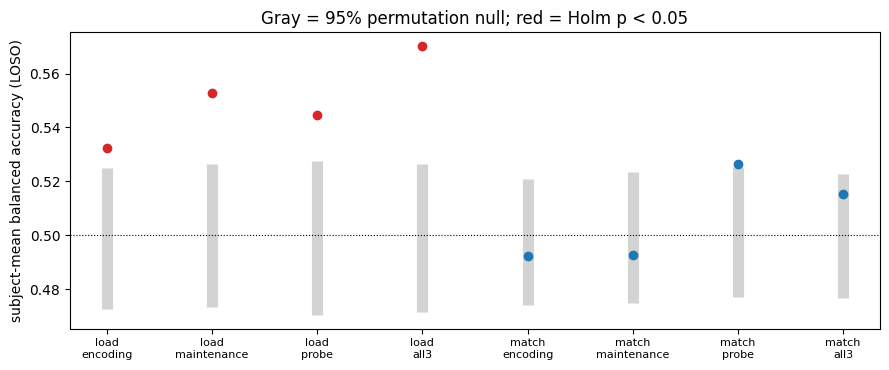

         target    features  bal_acc  null_hi  p_perm  p_holm  p_ttest
    load 4 vs 8    encoding   0.5323   0.5249  0.0060  0.0359   0.0004
    load 4 vs 8 maintenance   0.5527   0.5264  0.0020  0.0160   0.0221
    load 4 vs 8       probe   0.5445   0.5276  0.0060  0.0359   0.0099
    load 4 vs 8        all3   0.5703   0.5265  0.0020  0.0160   0.0072
match IN vs OUT    encoding   0.4922   0.5207  0.7166  1.0000   0.4074
match IN vs OUT maintenance   0.4925   0.5236  0.7026  1.0000   0.5216
match IN vs OUT       probe   0.5264   0.5255  0.0200  0.0798   0.0525
match IN vs OUT        all3   0.5151   0.5227  0.0898  0.2695   0.3417

Within-subject (session-grouped CV), secondary:
         target    features  n_subj  bal_acc  p_ttest
    load 4 vs 8    encoding      15   0.5188   0.4199
    load 4 vs 8 maintenance      15   0.6482   0.0000
    load 4 vs 8       probe      15   0.5829   0.0006
    load 4 vs 8        all3      15   0.6252   0.0000
match IN vs OUT    encoding      15   0.48

In [7]:
# ---- Cell F: gate figure and verdict ----
pr = res[res.group == "primary"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, r in pr.iterrows():
    ax.plot([i, i], [r.null_lo, r.null_hi], color="lightgray", lw=8, solid_capstyle="butt")
    ax.scatter(i, r.bal_acc, color="C3" if r.p_holm < 0.05 else "C0", zorder=3)
ax.axhline(0.5, color="k", lw=0.8, ls=":")
ax.set_xticks(range(len(pr))); ax.set_xticklabels([f"{t.split()[0]}\n{f}" for t, f in zip(pr.target, pr.features)], fontsize=8)
ax.set_ylabel("subject-mean balanced accuracy (LOSO)"); ax.set_title("Gray = 95% permutation null; red = Holm p < 0.05")
plt.tight_layout(); plt.show()

print(pr[["target", "features", "bal_acc", "null_hi", "p_perm", "p_holm", "p_ttest"]].round(4).to_string(index=False))
print("\nWithin-subject (session-grouped CV), secondary:")
print(pd.DataFrame(within_rows).round(4).to_string(index=False))
print("\nRegion-specific (exploratory, not Holm-corrected):")
print(res[res.group == "region"][["target", "features", "n_subj", "bal_acc", "p_perm"]].round(4).to_string(index=False))

ok = pr[(pr.p_holm < 0.05) & (pr.bal_acc > 0.5)]
print("\nGATE:", "PASS - brain features carry decodable task information:" if len(ok) else
      "NOT PASSED - no target decodes above chance across subjects after correction.")
if len(ok): print(ok[["target", "features", "bal_acc", "p_holm"]].round(4).to_string(index=False))

## 3.5 Surrogate stimuli, synthetic OOD sets, ceiling check

In [8]:
# ---- Cell G: letters, surrogate memory sets, synthetic evaluation suite ----
observed = sorted(M.ProbeLetter.dropna().astype(str).str.strip().unique())
alphabet = sorted("BCDFGHJKLMNPQRSTVWXZ")   # all 20 consonants; the data only shows 18 as probes (no J, M)
print("probe letters observed:", len(observed), "".join(observed), "| alphabet used:", len(alphabet))
assert set(observed) <= set(alphabet), "unexpected letter in the data"

train_letters, unseen_letters = split_alphabet(alphabet, n_unseen=6, seed=0)
tok = letter_tokens(alphabet)
train_pool = [tok[c] for c in train_letters]; unseen_pool = [tok[c] for c in unseen_letters]
n_tokens = 2 + len(alphabet)
print("train letters :", "".join(train_letters), "| held-out letters:", "".join(unseen_letters))

X_tok, y_tok = build_real_stimuli(M, train_pool, seed=0)          # one surrogate stimulus per real trial
suite = make_suite(train_pool, unseen_pool, n=1000, seed=123)

# --- label / design sanity ---
def contains_probe(row):
    mem = row[:MAX_LEN]; mem = mem[mem > 1]; return int(row[-1] in mem)
cp = np.array([contains_probe(r) for r in X_tok[C]])
assert (cp == y_tok[C]).all(), "label must equal 'probe in set'"
assert (np.array([(r[:MAX_LEN] > 1).sum() for r in X_tok[C]]) == M.SetSize.values[C]).all(), "set size must match"
assert set(X_tok[C][:, :MAX_LEN].ravel()) - {0} <= set(train_pool), "real trials must use training letters only"
for k, (Xs, ys, sz) in suite.items():
    assert (np.array([contains_probe(r) for r in Xs]) == ys).all()
    assert abs(ys.mean() - 0.5) < 0.02
assert set(suite["unseen_letters"][0][:, :MAX_LEN].ravel()) - {0} <= set(unseen_pool)
assert not (set(suite["id_4_6"][0][:, :MAX_LEN].ravel()) & set(unseen_pool))
print("PASS - labels = probe in set, sizes correct, letter pools disjoint, balanced")
print({k: (v[0].shape, sorted(set(v[2].tolist()))) for k, v in suite.items()})

probe letters observed: 18 BCDFGHKLNPQRSTVWXZ | alphabet used: 20
train letters : BCFHKLMNPQSTWX | held-out letters: DGJRVZ
PASS - labels = probe in set, sizes correct, letter pools disjoint, balanced
{'id_4_6': ((1000, 14), [4, 6]), 'size_8': ((1000, 14), [8]), 'len_10': ((1000, 14), [10]), 'len_12': ((1000, 14), [12]), 'unseen_letters': ((1000, 14), [4, 5])}


n_train=100 done (25s)
n_train=300 done (42s)
n_train=1000 done (61s)
n_train=3000 done (79s)
        id_4_6        size_8        len_10        len_12        unseen_letters       
          mean    std   mean    std   mean    std   mean    std           mean    std
n_train                                                                              
100      0.518  0.008  0.512  0.007  0.522  0.003  0.503  0.010          0.517  0.033
300      0.505  0.012  0.522  0.011  0.513  0.011  0.530  0.006          0.525  0.025
1000     0.570  0.032  0.554  0.017  0.550  0.005  0.550  0.012          0.515  0.034
3000     0.703  0.018  0.653  0.006  0.646  0.025  0.600  0.010          0.564  0.034


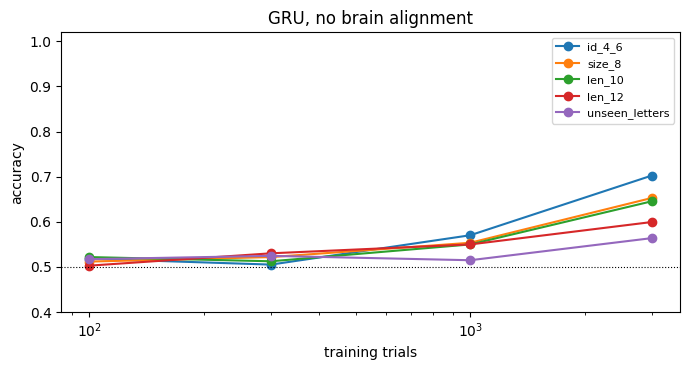


READING THE RESULT
- ID near 1.0 AND all OOD near 1.0  -> ceiling: alignment cannot help; use small n_train or harder OOD sets
- ID near 0.5                       -> floor: the baseline is not learning; fix the model before Phase 5
- ID high, OOD clearly lower        -> headroom exists on the OOD axes: this is the setting we want
Largest-n result: {'id_4_6': 0.703, 'size_8': 0.653, 'len_10': 0.646, 'len_12': 0.6, 'unseen_letters': 0.564}


In [9]:
# ---- Cell H: ceiling check - is the task too easy, too hard, or does it leave headroom? ----
# A plain GRU trained ONLY on synthetic sets of size 4/6 (no brain data), tested on seen and OOD sets.
# This is NOT the Phase 5 baseline; it only tells us how much room alignment has to help.
import torch, time
device = "cuda" if torch.cuda.is_available() else "cpu"
N_TRAIN = [100, 300, 1000, 3000]; SEEDS = [0, 1, 2]
rows = []; t0 = time.time()
for n in N_TRAIN:
    Xtr, ytr, _ = make_synth(n, [4, 6], train_pool, seed=1000 + n)
    for s in SEEDS:
        model = train_gru(Xtr, ytr, n_tokens, seed=s, steps=3000, device=device)
        rows.append(dict(n_train=n, seed=s, **{k: gru_accuracy(model, v[0], v[1], device) for k, v in suite.items()}))
    print(f"n_train={n} done ({time.time() - t0:.0f}s)")
ce = pd.DataFrame(rows)
summ = ce.groupby("n_train")[list(suite)].agg(["mean", "std"]).round(3)
print(summ.to_string())
ce.to_csv(OUT3 / "ceiling_check.csv", index=False)

m = ce.groupby("n_train")[list(suite)].mean()
fig, ax = plt.subplots(figsize=(7, 3.8))
for k in suite: ax.plot(m.index, m[k], marker="o", label=k)
ax.set_xscale("log"); ax.axhline(0.5, color="k", ls=":", lw=0.8); ax.set_ylim(0.4, 1.02)
ax.set_xlabel("training trials"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8); ax.set_title("GRU, no brain alignment")
plt.tight_layout(); plt.show()

full = m.loc[N_TRAIN[-1]]
print("\nREADING THE RESULT")
print("- ID near 1.0 AND all OOD near 1.0  -> ceiling: alignment cannot help; use small n_train or harder OOD sets")
print("- ID near 0.5                       -> floor: the baseline is not learning; fix the model before Phase 5")
print("- ID high, OOD clearly lower        -> headroom exists on the OOD axes: this is the setting we want")
print("Largest-n result:", full.round(3).to_dict())

## Save everything for Phase 4

In [10]:
# ---- Cell I: persist and final checklist ----
json.dump([{k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in f.items()} for f in folds],
          open(OUT3 / "folds.json", "w"))
fold_df.to_csv(OUT3 / "fold_summary.csv", index=False)
np.savez_compressed(OUT3 / "real_stimuli.npz", X_tok=X_tok, y=y_tok, train_pool=train_pool,
                    unseen_pool=unseen_pool, n_tokens=n_tokens, alphabet=np.array(alphabet))
np.savez_compressed(OUT3 / "synth_suite.npz", **{f"{k}_{part}": arr for k, v in suite.items()
                                                 for part, arr in zip(["X", "y", "size"], v)})
for f_ in ["X_region.npy", "M_region.csv"]:
    import shutil; shutil.copy(P2 / f_, OUT3 / f_)             # so Phase 4 needs only ONE input dataset

gate_pass = bool(((res[res.group == "primary"].p_holm < 0.05) & (res[res.group == "primary"].bal_acc > 0.5)).any())
final = {
    "3.1 encoder smoke test passed": True,
    "3.2 folds built (5, subject-grouped)": len(folds) == 5,
    "3.3 leakage checks passed": bool(chk.values.all()),
    "3.4 decoding gate passed (brain carries task info)": gate_pass,
    "3.5 stimuli + synthetic suite built": True,
    "3.5 ceiling check run": len(ce) == len(N_TRAIN) * len(SEEDS),
}
for k, v in final.items(): print("PASS" if v else "CHECK", "-", k)
print()
for p in sorted(OUT3.iterdir()): print(f"{p.name:28s} {p.stat().st_size / 1e6:8.2f} MB")
print("\nNext: Save Version (commit), then Output -> New Dataset (e.g. cdb2m-phase3) containing phase3_out.")

PASS - 3.1 encoder smoke test passed
PASS - 3.2 folds built (5, subject-grouped)
PASS - 3.3 leakage checks passed
PASS - 3.4 decoding gate passed (brain carries task info)
PASS - 3.5 stimuli + synthetic suite built
PASS - 3.5 ceiling check run

M_region.csv                     0.23 MB
X_region.npy                     4.29 MB
__pycache__                      0.00 MB
cdb2m_lib.py                     0.01 MB
ceiling_check.csv                0.00 MB
decode_results.csv               0.00 MB
decode_within_subject.csv        0.00 MB
fold_summary.csv                 0.00 MB
folds.json                       0.09 MB
real_stimuli.npz                 0.03 MB
synth_suite.npz                  0.05 MB

Next: Save Version (commit), then Output -> New Dataset (e.g. cdb2m-phase3) containing phase3_out.
